# Phân đoạn pha và đếm rep squat

Đọc landmark đã trích xuất, đổi tọa độ chuẩn hóa về pixel, tính góc 2D và lọc Savitzky–Golay. Các mốc frame đánh số từ 0. Ngưỡng đếm 105°/160° chỉ là cấu hình thử nghiệm; rep nông hơn 105° sẽ không được đếm. Kết quả chưa được kiểm chứng bằng nhãn độc lập.

Lưu ý: để khảo sát dữ liệu hiện có, notebook vẫn dùng landmark có visibility < 0.5 và báo số frame liên quan. Số đo ở các frame đó có độ tin cậy thấp; chưa có quality gate.

**Lưu ý tái lập:** Notebook này ghi lại baseline với ngưỡng phát hiện đáy 105°. Module hiện dùng ngưỡng thử nghiệm 150° để nhận diện rep nông; kết quả hiện tại vẫn chưa có nhãn độc lập.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import asdict
root = Path.cwd().resolve()
while not (root / "backend").exists():
    if root == root.parent:
        raise RuntimeError("Không tìm thấy thư mục dự án")
    root = root.parent
sys.path.insert(0, str(root / "backend"))
from app.core.geometry import calculate_angle_2d, calculate_trunk_lean, detect_dominant_side
from app.core.pose import FramePose
from app.core.smoothing import smooth_signal_1d
from app.core.phases import segment_squat_reps, SquatPhase

In [2]:
def analyze(name):
    data = json.loads((root / "data/processed/landmarks" / (name + ".json")).read_text(encoding="utf-8"))
    frames = data["frames"]
    objects = [FramePose(**{k: f[k] for k in ("frame_idx", "timestamp_ms", "is_detected", "landmarks", "world_landmarks")}) for f in frames]
    side = data.get("dominant_side") or detect_dominant_side(objects)
    signals = {key: [] for key in ("knee", "hip", "trunk")}
    low_visibility = 0
    for frame in frames:
        landmarks = {lm["name"]: lm for lm in frame["landmarks"]}
        names = [side + "_" + part for part in ("shoulder", "hip", "knee", "ankle")]
        if not frame["is_detected"] or any(name not in landmarks for name in names):
            for values in signals.values(): values.append(np.nan)
            continue
        if any(landmarks[name].get("visibility", 0) < 0.5 for name in names): low_visibility += 1
        p = [(landmarks[name]["x"] * data["width"], landmarks[name]["y"] * data["height"]) for name in names]
        signals["knee"].append(calculate_angle_2d(*p[1:]))
        signals["hip"].append(calculate_angle_2d(*p[:3]))
        signals["trunk"].append(calculate_trunk_lean(p[0], p[1]))
    for key, values in signals.items():
        if not np.isfinite(values).all():
            raise ValueError(f"{name}: thiếu landmark tin cậy; cần xử lý trước khi phân đoạn")
        signals[key] = smooth_signal_1d(values)
    reps, phases = segment_squat_reps(signals["knee"], data["fps"], hip_angles=signals["hip"], trunk_lean=signals["trunk"], bottom_threshold=105.0)
    print(f"{name}: {side}, {len(reps)} rep, đáy {[r.bottom_frame for r in reps]}; {low_visibility}/{len(frames)} frame có khớp visibility < 0.5 (kết quả cần kiểm tra)")
    for rep in reps: print(asdict(rep))
    return data, signals, reps, phases

In [3]:
results = {name: analyze(name) for name in ("test_squat", "sample_squat")}

test_squat: right, 1 rep, đáy [90]; 17/178 frame có khớp visibility < 0.5 (kết quả cần kiểm tra)
{'rep_id': 1, 'start_frame': 73, 'bottom_frame': 90, 'end_frame': 103, 'start_time_s': 2.433333333333333, 'bottom_time_s': 3.0, 'end_time_s': 3.433333333333333, 'eccentric_duration_s': 0.5666666666666667, 'pause_duration_s': 0.06666666666666667, 'concentric_duration_s': 0.43333333333333335, 'total_duration_s': 1.0, 'min_knee_angle': 62.18981800136808, 'max_trunk_lean': 20.112117824933698, 'trunk_lean_at_bottom': 19.322456029019868, 'max_knee_over_toe_px': None, 'max_heel_rise_px': None}
sample_squat: right, 0 rep, đáy []; 52/180 frame có khớp visibility < 0.5 (kết quả cần kiểm tra)


In [4]:
# Phân tích độ nhạy: giữ nguyên ngưỡng góc, chỉ hạ thời lượng tối thiểu.
data, signals, _, _ = results["test_squat"]
short_reps, _ = segment_squat_reps(signals["knee"], data["fps"], hip_angles=signals["hip"], trunk_lean=signals["trunk"], min_duration_s=0.9, bottom_threshold=105.0)
print("Ngưỡng 0.9 giây:", [(r.start_frame, r.bottom_frame, r.end_frame, round(r.total_duration_s, 3)) for r in short_reps])
print("Thời lượng dựa trên lần vượt ngưỡng 160°, không phải thời lượng gán nhãn thủ công.")

Ngưỡng 0.9 giây: [(73, 90, 103, 1.0), (118, 133, 146, 0.933)]
Thời lượng dựa trên lần vượt ngưỡng 160°, không phải thời lượng gán nhãn thủ công.


Theo thiết lập yêu cầu 1.0 giây, rep thứ hai bị loại vì khoảng từ frame 118 tới 146 chỉ khoảng 0.933 giây. Khi thử ngưỡng 0.9 giây, hệ thống nhận hai rep với đáy 90 và 133. Không thể đồng thời áp dụng ngưỡng 1.0 giây theo các mốc này và đếm cả hai rep; cần nhãn thủ công để đánh giá cách xác định đầu/cuối rep.

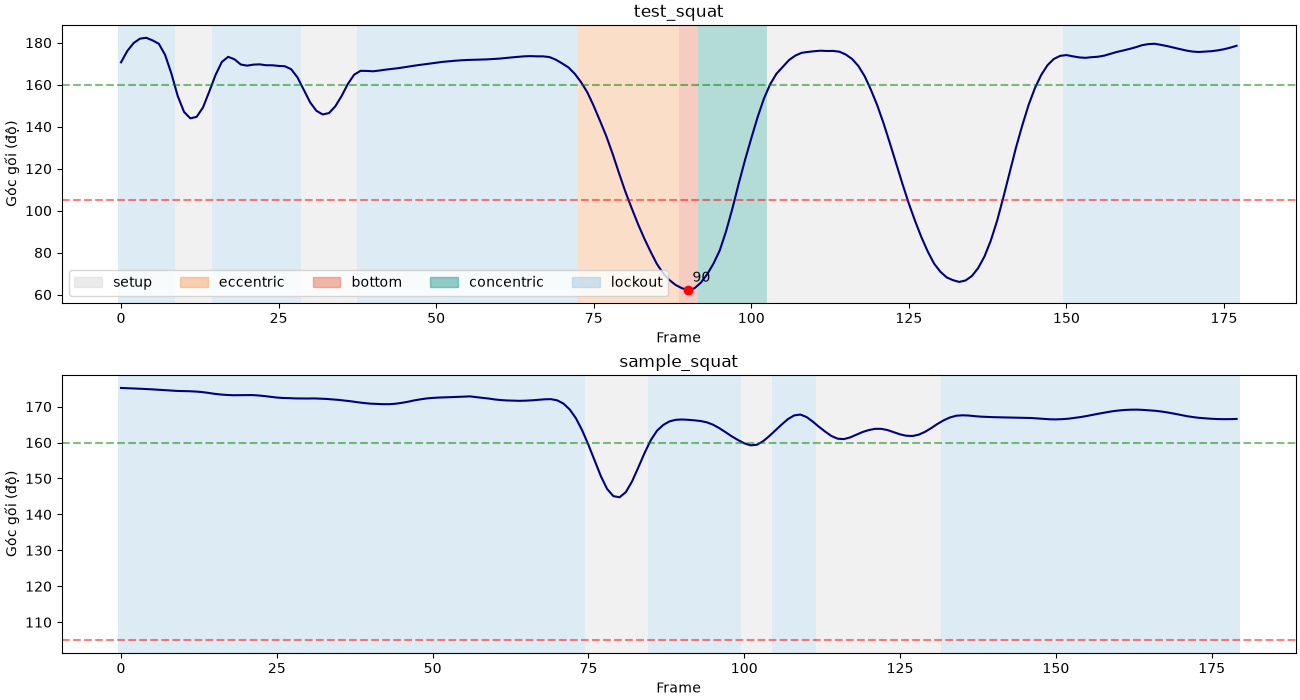

In [5]:
colors = {SquatPhase.UNKNOWN: "#ffffff", SquatPhase.SETUP: "#d9d9d9", SquatPhase.ECCENTRIC: "#f4a261", SquatPhase.BOTTOM: "#e76f51", SquatPhase.CONCENTRIC: "#2a9d8f", SquatPhase.LOCKOUT: "#9ecae1"}
fig, axes = plt.subplots(len(results), 1, figsize=(13, 7), constrained_layout=True)
for ax, (name, (data, signals, reps, phases)) in zip(axes, results.items()):
    for i, phase in enumerate(phases):
        ax.axvspan(i - 0.5, i + 0.5, color=colors[phase], alpha=.35, linewidth=0)
    ax.plot(signals["knee"], color="navy", label="Góc gối sau lọc")
    for rep in reps:
        ax.scatter(rep.bottom_frame, rep.min_knee_angle, color="red", zorder=3)
        ax.annotate(str(rep.bottom_frame), (rep.bottom_frame, rep.min_knee_angle), xytext=(3, 6), textcoords="offset points")
    ax.axhline(105, color="red", linestyle="--", alpha=.5)
    ax.axhline(160, color="green", linestyle="--", alpha=.5)
    ax.set(title=name, xlabel="Frame", ylabel="Góc gối (độ)")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=color, alpha=.5, label=phase.value) for phase, color in colors.items()], loc="lower left", ncol=5)
plt.show()

Điểm đáy được lấy từ cực tiểu của tín hiệu đã lọc, không ép theo frame kỳ vọng. Khoảng dừng đáy là đoạn liên tiếp trong phạm vi 2° quanh cực tiểu; thời lượng này nằm trong thời lượng hạ và đẩy đã tính theo frame đáy. Đồ thị và số đo chỉ có ý nghĩa khi landmark đủ tin cậy, camera gần góc nghiêng và thời gian video đúng FPS.